# 1. 라이브러리 설치 및 불러오기

In [2]:
!pip install finance-datareader

import FinanceDataReader as fdr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


# 2. 삼성전자 주가 데이터 불러오기

In [3]:
samsung = fdr.DataReader('005930', '2016')
print(samsung)

              Open    High     Low   Close    Volume    Change
Date                                                          
2016-01-04   25200   25200   24100   24100    306939 -0.043651
2016-01-05   24040   24360   23720   24160    216002  0.002490
2016-01-06   24160   24160   23360   23500    366752 -0.027318
2016-01-07   23320   23660   23020   23260    282388 -0.010213
2016-01-08   23260   23720   23260   23420    257763  0.006879
...            ...     ...     ...     ...       ...       ...
2026-11-03  220500  223000  217000  222000  13391670 -0.034783
2026-11-04  226500  228000  208000  221500  22248738 -0.002252
2026-11-05  213000  213500  199800  201500  24657743 -0.090293
2026-11-06  180000  196500  179200  193500  35516270 -0.039702
2026-11-09  187200  195000  187000  193400   9075967 -0.000517

[2660 rows x 6 columns]


# 3. 시가(Open) 데이터 추출 및 정규화

In [4]:
openValues = samsung[['Open']]

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0, 1))
scaled = scaler.fit_transform(openValues)

# 4. 학습 데이터와 테스트 데이터 분리

In [5]:
TEST_SIZE = 200

train_data = scaled[:-TEST_SIZE]
test_data = scaled[-TEST_SIZE:]

# 5. 시계열 학습 데이터 생성 함수

> X: 과거 window일의 주가 / y: 그다음 날의 주가


In [6]:
def make_sample(data, window):
    train = []
    target = []

    for i in range(len(data)-window):
        train.append(data[i:i+window])
        target.append(data[i+window])

    return np.array(train), np.array(target)

# 6. 학습용 X, y 데이터 생성

> Window Size = 30일 -> 다른 값(10, 20, 60 등)으로 변경하여 실습 가능



In [7]:
X_train, y_train = make_sample(train_data, 30)

# 7. LSTM 모델 생성

In [8]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM

model = Sequential()

model.add(LSTM(16,
               input_shape=(X_train.shape[1], 1),
               activation='tanh',
               return_sequences=False))

model.add(Dense(1))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


# 8. 모델 컴파일 및 학습

In [9]:
model.compile(optimizer='adam', loss='mean_squared_error')

model.fit(X_train, y_train, epochs=100, batch_size=16)

Epoch 1/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 8.5135e-04
Epoch 2/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 6.5509e-05
Epoch 3/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 6.3922e-05
Epoch 4/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 6.2874e-05
Epoch 5/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 6.2992e-05
Epoch 6/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 6.0990e-05
Epoch 7/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 6.0636e-05
Epoch 8/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 6.0108e-05
Epoch 9/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.6124e-05
Epoch 10/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.4764e-05
Epoch 11/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.3305e-05
Epoch 12/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.5570e-05
Epoch 13/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.0592e-05
Epoch 14/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss

# 9. 테스트용 X, y 데이터 생성 및 주가 예측

> 학습 데이터와 동일한 Window Size 사용





In [10]:
X_test, y_test = make_sample(test_data, 30)

pred = model.predict(X_test)

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


# 10. 실제 주가와 예측 주가 시각화

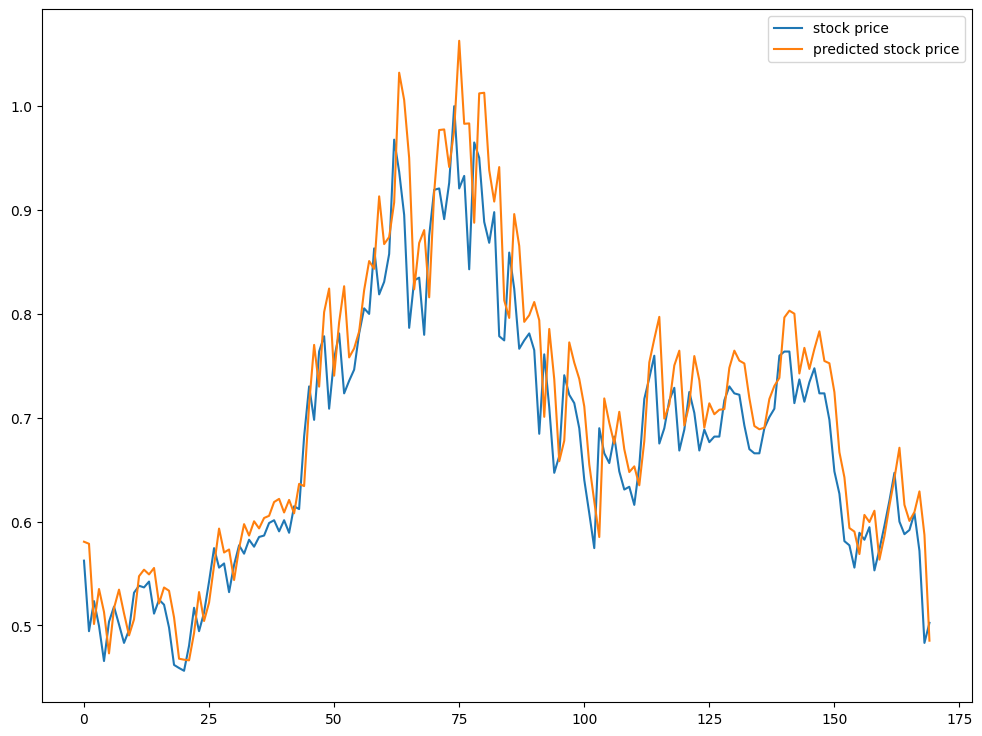

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 9))
plt.plot(y_test, label='stock price')
plt.plot(pred, label='predicted stock price')
plt.legend()
plt.show()